# Prototipo de riesgo de crédito (primer borrador)

Este es el notebook tal como lo escribiría un data scientist en su primera tarde: funciona, imprime un AUC y dibuja un gráfico. Es el punto de partida de la sesión de MLOps. Léelo con ojo crítico: al final hay una lista de nueve problemas.

## 1. Cargar los datos

In [1]:
import glob
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

files = sorted(glob.glob("../data/raw/applications/*.parquet"))
apps = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
outcomes = pd.read_parquet("../data/raw/outcomes.parquet")
print(len(files), "archivos,", len(apps), "préstamos")

84 archivos, 210000 préstamos


## 2. Construir la etiqueta

In [2]:
apps["origination_month"] = pd.to_datetime(apps["origination_month"])
outcomes["default_date"] = pd.to_datetime(outcomes["default_date"])
df = apps.merge(outcomes, on="loan_id", how="left")
limit = df["origination_month"] + pd.DateOffset(months=12)
df["default_12m"] = (df["default_date"].notna() & (df["default_date"] <= limit)).astype(int)
print("tasa de default:", round(df["default_12m"].mean(), 4))
print("último mes de originación:", df["origination_month"].max().date())
print(df.groupby(df["origination_month"].dt.year)["default_12m"].mean().round(4))

tasa de default: 0.0948
último mes de originación: 2025-12-01
origination_month
2019    0.0944
2020    0.1015
2021    0.0944
2022    0.0986
2023    0.1030
2024    0.1201
2025    0.0518
Name: default_12m, dtype: float64


La etiqueta se calculó para todos los meses, incluso los más recientes. Mira la tasa por año: ¿por qué cae al final? ¿Habrán pasado ya 12 meses para todos esos préstamos?

## 3. Preparar las variables

In [3]:
cat_cols = ["product", "region", "channel"]
num_cols = [
    "bureau_score",
    "monthly_income_pen",
    "debt_to_income",
    "loan_amount_pen",
    "term_months",
    "age",
    "months_at_job",
    "num_active_lenders",
    "max_days_past_due_12m",
]
for c in cat_cols:
    df[c] = df[c].astype("category")
X = df[num_cols + cat_cols]
y = df["default_12m"]

## 4. Entrenar y evaluar con un split aleatorio

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    enable_categorical=True,
    tree_method="hist",
    n_jobs=4,
    random_state=42,
)
model.fit(X_train, y_train)
auc_random = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"AUC split aleatorio: {auc_random:.3f}")

AUC split aleatorio: 0.797


## 5. ¿Y si evaluamos hacia el futuro?

In [5]:
month = df["origination_month"]
train_mask = month <= "2023-12-01"
test_mask = (month >= "2024-01-01") & (month <= "2024-12-01")
oot_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    enable_categorical=True,
    tree_method="hist",
    n_jobs=4,
    random_state=42,
)
oot_model.fit(X[train_mask], y[train_mask])
auc_oot = roc_auc_score(y[test_mask], oot_model.predict_proba(X[test_mask])[:, 1])
print(f"AUC split aleatorio: {auc_random:.3f}")
print(f"AUC fuera de tiempo: {auc_oot:.3f}")
print(f"diferencia: {auc_random - auc_oot:.3f}")

AUC split aleatorio: 0.797
AUC fuera de tiempo: 0.789
diferencia: 0.008


## 6. Explicabilidad con SHAP

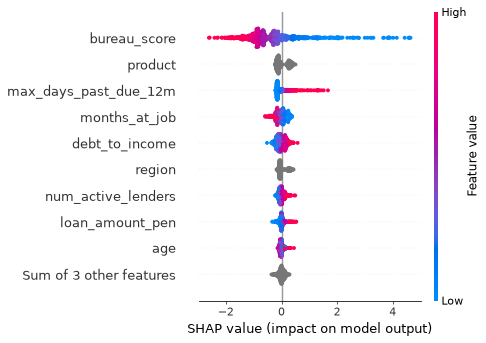

In [6]:
import shap

sample = X_test.sample(1000, random_state=42)
shap_values = shap.TreeExplainer(model)(sample)
shap.plots.beeswarm(shap_values, show=False)
plt.gcf().set_size_inches(7, 5)
plt.gcf().set_dpi(70)
plt.tight_layout()
plt.show()

## Lo que está mal con este notebook

1. Rutas fijas (hardcoded): `../data/raw/...` solo funciona desde esta carpeta.
2. Etiquetas usadas antes de existir: los préstamos recientes no han cumplido sus 12 meses, pero se etiquetaron igual.
3. Split aleatorio sobre datos ordenados en el tiempo: el AUC sale optimista.
4. Parámetros sin registro: `n_estimators`, `max_depth` y demás viven como números mágicos en la celda.
5. El modelo no se guarda: al cerrar el kernel se pierde.
6. No hay validación de entradas: si cambia una columna o una unidad, nadie avisa.
7. El preprocesamiento vive fuera del modelo (el `astype("category")` manual): quien use el modelo debe repetirlo a mano.
8. Imposible de programar o servir: es un notebook, no un proceso ni una API.
9. No queda registro de qué datos produjeron el resultado.